In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 
from scipy.stats import pearsonr
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

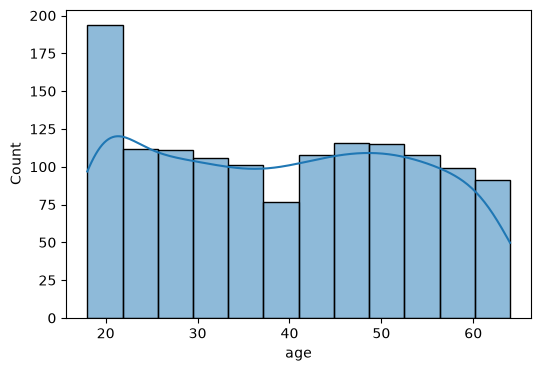

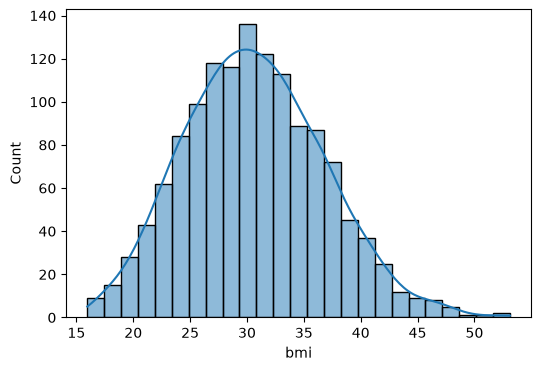

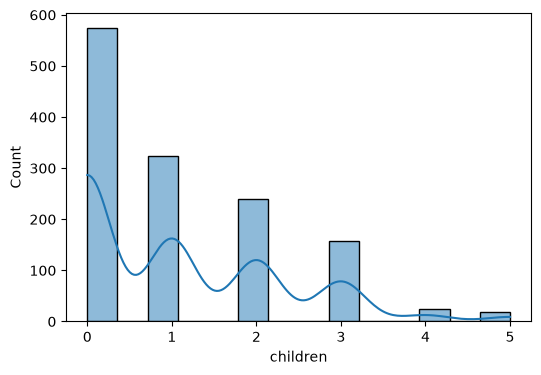

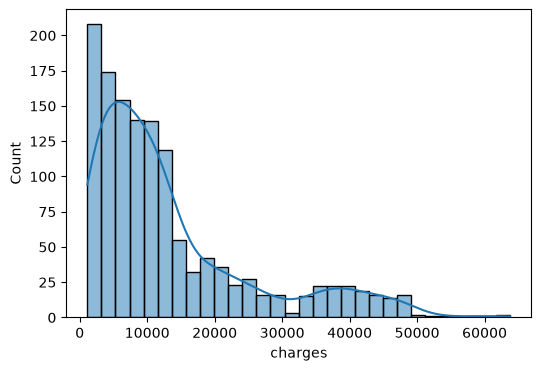

In [8]:
num_cols = ['age', 'bmi', 'children', 'charges']
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(data = df[col],kde = True)

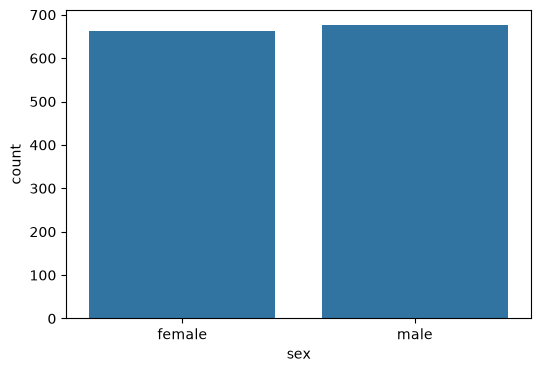

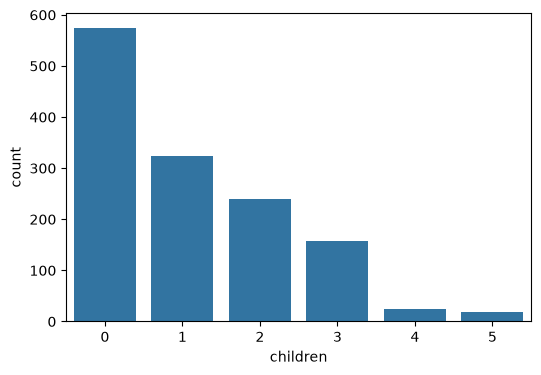

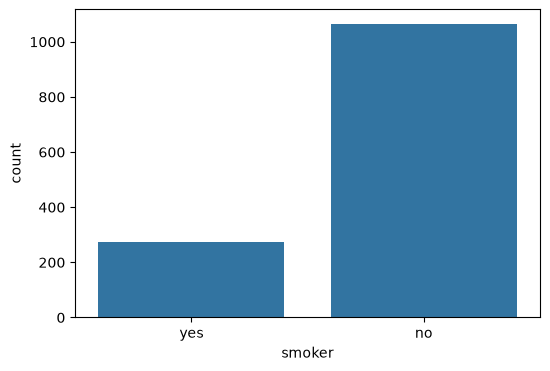

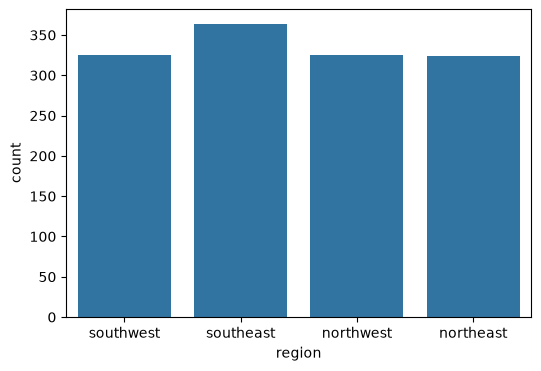

In [9]:
alpha_cols = [ 'sex','children', 'smoker', 'region']
for col in alpha_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x= df[col])

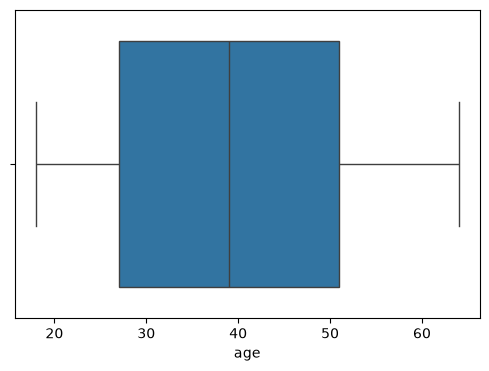

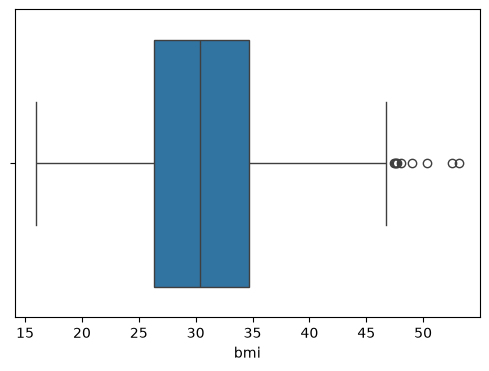

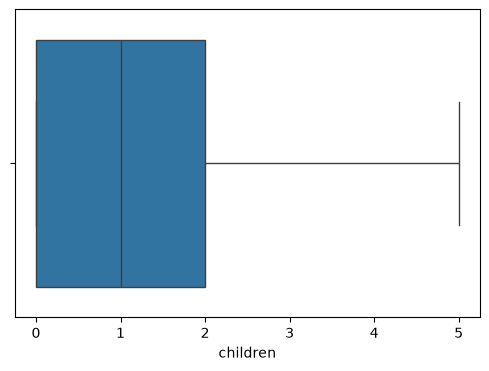

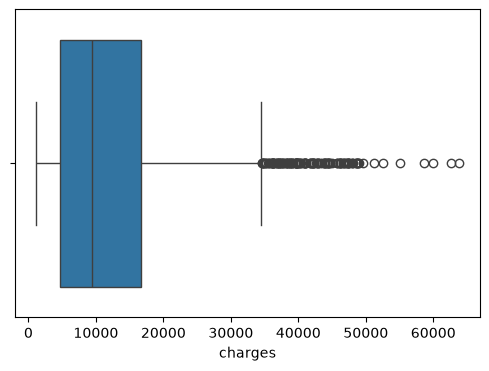

In [10]:
num_cols = ['age', 'bmi', 'children', 'charges']
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

<Axes: >

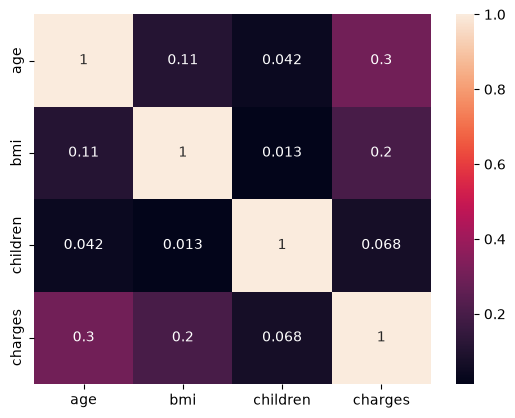

In [11]:
sns.heatmap(df[num_cols].corr(),annot=True)

In [12]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(1)

In [14]:
df.drop_duplicates(inplace=True)
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


we will convert non numeric columns to numeric columns :-


In [15]:
df['sex']=df['sex'].map({'male':1,'female':0})
df['smoker'] = df['smoker'].map({'yes':1,'no':0})

In [16]:
df.rename(columns={'sex':'is_male','smoker':'is_smoker'},inplace=True)
df = pd.get_dummies(df,columns=['region'],dtype=int,drop_first=True)

In [17]:
df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal Weight', 'Overweight', 'Obese'],
    right=False
)

In [18]:
df=pd.get_dummies(df,columns=['bmi_category'],dtype=int,drop_first=True)
df1 = df.copy()

In [19]:
column = ['age','bmi','children']
scaler = StandardScaler()
df1[column] = scaler.fit_transform(df1[column])
tmp = pd.qcut(df1['charges'],q=4,labels=False)

In [20]:
column = ['age','is_male','bmi','children','is_smoker','region_northwest','region_southeast',
          'region_southwest','bmi_category_Normal Weight','bmi_category_Overweight','bmi_category_Obese']
corelation = {
    feature : pearsonr(df1[feature],tmp)[0]
    for feature in column
}
df2 = pd.DataFrame(list(corelation.items()),columns=['feature','person corealtion'])
df2

,feature,person corealtion
0,age,0.489463
1,is_male,0.016396
2,bmi,0.092411
3,children,0.111070
4,is_smoker,0.648323
5,region_northwest,-0.019723
6,region_southeast,0.018643
7,region_southwest,-0.034512
8,bmi_category_Normal Weight,-0.050496
9,bmi_category_Overweight,-0.031829


In [21]:
alpha = 0.05
chi_test_result = {}
column = ['is_male','children','is_smoker','region_northwest','region_southeast',
          'region_southwest','bmi_category_Normal Weight','bmi_category_Overweight','bmi_category_Obese']
for col in column:
    contingency = pd.crosstab(df1[col],tmp)
    chi2,p_value,_,_=chi2_contingency(contingency)
    decision = "reject null hypothesis(KEEP FEATURE)" if p_value<alpha else "accept null hypothesis(REMOVE FEATURE)"
    chi_test_result[col] = {
        'chi2 value':chi2,
        'P_Value': p_value,
        'Decision': decision
    }
chi2_df = pd.DataFrame(chi_test_result).T
chi2_df = chi2_df.sort_values(by='P_Value')

In [22]:
chi2_df

,chi2 value,P_Value,Decision
is_smoker,848.219178,0.0,reject null hypothesis(KEEP FEATURE)
children,138.659313,0.0,reject null hypothesis(KEEP FEATURE)
region_southeast,15.998167,0.001135,reject null hypothesis(KEEP FEATURE)
is_male,10.258784,0.01649,reject null hypothesis(KEEP FEATURE)
bmi_category_Obese,8.515711,0.036473,reject null hypothesis(KEEP FEATURE)
region_southwest,5.091893,0.165191,accept null hypothesis(REMOVE FEATURE)
bmi_category_Overweight,4.25149,0.235557,accept null hypothesis(REMOVE FEATURE)
bmi_category_Normal Weight,3.739475,0.291005,accept null hypothesis(REMOVE FEATURE)
region_northwest,1.13424,0.768815,accept null hypothesis(REMOVE FEATURE)


In [23]:
df1.head()

,age,is_male,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal Weight,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,0,-0.453160,-0.909234,1,16884.92400,0,0,1,0,1,0
1,-1.511647,1,0.509422,-0.079442,0,1725.55230,0,1,0,0,0,1
2,-0.799350,1,0.383155,1.580143,0,4449.46200,0,1,0,0,0,1
3,-0.443201,1,-1.305052,-0.909234,0,21984.47061,1,0,0,1,0,0
4,-0.514431,1,-0.292456,-0.909234,0,3866.85520,1,0,0,0,1,0


In [24]:
final_data=df[['age','is_smoker','children','region_southeast','is_male','bmi','bmi_category_Obese','charges']]
cols = ['age','is_smoker','children','region_southeast','is_male','bmi','bmi_category_Obese']
final_data

,age,is_smoker,children,region_southeast,is_male,bmi,bmi_category_Obese,charges
0,19,1,0,0,0,27.900,0,16884.92400
1,18,0,1,1,1,33.770,1,1725.55230
2,28,0,3,1,1,33.000,1,4449.46200
3,33,0,0,0,1,22.705,0,21984.47061
4,32,0,0,0,1,28.880,0,3866.85520
...,...,...,...,...,...,...,...,...
1333,50,0,3,0,1,30.970,1,10600.54830
1334,18,0,0,0,0,31.920,1,2205.98080
1335,18,0,0,1,0,36.850,1,1629.83350
1336,21,0,0,0,0,25.800,0,2007.94500


In [25]:
from sklearn.model_selection import train_test_split
x = final_data.drop('charges',axis=1)
y = final_data['charges']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.23,random_state=42)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

col = ['age','is_smoker','children','region_southeast','is_male','bmi','bmi_category_Obese']
prep = ColumnTransformer([('scale',StandardScaler(),col)],remainder = 'passthrough')
lr = Pipeline([('prep',prep),('model',LinearRegression())])
lr.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','is_smoker','children',...,'is_male','bmi','bmi_category_Obese']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with t

In [27]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
n=x_test.shape[0]
p=x_test.shape[1]
pred = (lr.predict(x_test))
actual= (y_test)
r2 = r2_score(actual,pred)
print("R2 :", r2)
print("Adjusted R2",1-(((1-r2)*(n-1)/(n-p-1))))
print("MAE :" ,mean_absolute_error(actual,pred))
print("MSE :", mean_squared_error(actual,pred))

R2 : 0.7965622752101394
Adjusted R2 0.7918153949650427
MAE : 4265.841624237568
MSE : 36347109.915204264


In [28]:
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
models={
    'Linear' : lr,
    'RandomForest':RandomForestRegressor(random_state=42),
    'GradientBoosting':GradientBoostingRegressor(random_state=42)
}
for name , m in models.items():
    s = cross_val_score(m,x_train,y_train,cv=5,scoring='r2')
    print(name,s.mean().round(3))

Linear 0.733
RandomForest 0.808
GradientBoosting 0.834


In [29]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),{
    'n_estimators' : [100,200,300],
    'max_depth': [2,3,4],
    'learning_rate': [0.2,0.5,0.1]
    },cv=5,scoring='r2',n_jobs=-1
)
grid.fit(x_train,y_train)
best  = grid.best_estimator_

In [30]:
pred = (best.predict(x_test))
actual= (y_test)
r2 = r2_score(actual,pred)
print("R2 :", r2)
print("Adjusted R2",1-(((1-r2)*(n-1)/(n-p-1))))
print("MAE :" ,mean_absolute_error(actual,pred))
print("MSE :", mean_squared_error(actual,pred))

R2 : 0.8885504089569699
Adjusted R2 0.8859499184992992
MAE : 2550.3740023092237
MSE : 19912091.230030697


In [31]:
import joblib
joblib.dump(best,"insurance_model.pkl")
joblib.dump(cols,"columns.pkl")

['columns.pkl']